In [ ]:
#Surg_BM - variants called
#Surg_Bl - variants called
#Surg_Hip - variants called
#Pm_Ctx - variants called
#Pm_Bl - variants called


BM and PM blood variant names identical: True

BM barcode examples:
['AAACGAAAGCTTACCA-1', 'AAACGAAAGGACTTTC-1', 'AAACGAAAGGTACATA-1', 'AAACGAACAAAGCTGG-1', 'AAACGAACAAGAGCGT-1']

PM blood barcode examples:
['AAACGAAAGAGGAATG-1', 'AAACGAAAGCGTTGCC-1', 'AAACGAAAGGCAGTGT-1', 'AAACGAAAGTGAGTTA-1', 'AAACGAACACCAAGGA-1']

Exact shared barcodes: 62


In [59]:
import numpy as np
import pandas as pd
from scipy import sparse

rows = []

for name, obj in samples.items():
    key = "coverage_per_cell" if "coverage_per_cell" in obj.obsm else "variant_coverage"
    cov = obj.obsm[key]

    if sparse.issparse(cov):
        per_cell = np.asarray(cov.mean(axis=1)).ravel()
        nonzero_fraction = cov.count_nonzero() / (cov.shape[0] * cov.shape[1])
    else:
        cov = np.asarray(cov)
        per_cell = np.nanmean(cov, axis=1)
        nonzero_fraction = np.count_nonzero(np.nan_to_num(cov)) / cov.size

    rows.append({
        "sample": name,
        "coverage_shape": cov.shape,
        "mean_depth": np.nanmean(per_cell),
        "median_cell_depth": np.nanmedian(per_cell),
        "zero_depth_cells": int(np.sum(per_cell == 0)),
        "nonzero_entries_%": 100 * nonzero_fraction,
    })

print(pd.DataFrame(rows).set_index("sample").round(2).to_string())

         coverage_shape  mean_depth  median_cell_depth  zero_depth_cells  nonzero_entries_%
sample                                                                                     
Surg_BM    (6094, 4701)        0.29               0.00              6026               1.07
Surg_Bl    (8415, 7355)       35.68              33.75                72              94.31
Surg_Hip   (3346, 3848)       41.57              35.43                43              94.13
Pm_Ctx     (1212, 1083)       13.08               6.45                12              78.26
Pm_Bl      (7628, 4701)       20.73              17.33               751              86.32


2026-10-29 14:49:46 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-29 14:49:46 - INFO - shutil.rmtree worked.
2026-10-29 14:49:46 - INFO - Chromium init'ed with kwargs {}
2026-10-29 14:49:46 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-29 14:49:46 - INFO - Temp directory created: /tmp/tmpe7xr13s7.
2026-10-29 14:49:46 - INFO - Opening browser.
2026-10-29 14:49:46 - INFO - Temp directory created: /tmp/tmphjdks83a.
2026-10-29 14:49:46 - INFO - Temporary directory at: /tmp/tmphjdks83a
2026-10-29 14:49:46 - INFO - Conforming 1 to file:///tmp/tmpe7xr13s7/index.html
2026-10-29 14:49:46 - INFO - Waiting on all navigates
2026-10-29 14:49:48 - INFO - All navigates done, putting them all in queue.
2026-10-29 14:49:48 - INFO - Getting tab from queue (has 1)
2026-10-29 14:49:48 - INFO - Got C58F
2026-10-29 14:49:48 - INFO - Processing bmtDNA_Coverageb.png
2026-10-29 14:49:48 

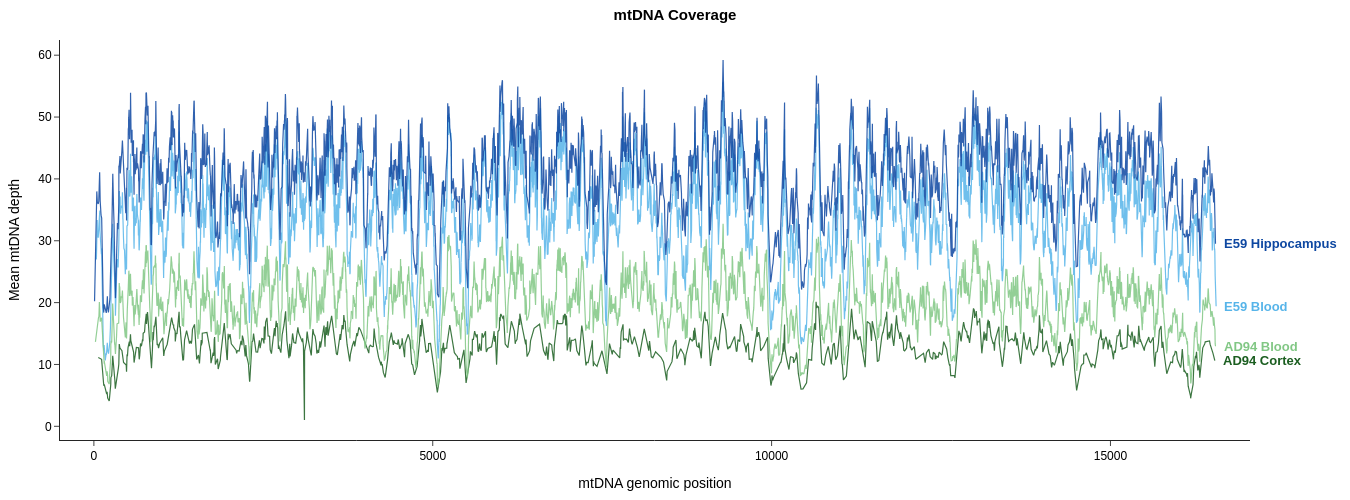

In [98]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from scipy import sparse


samples = {
    "E59 Blood": Surg_Bl,
    "E59 Hippocampus": Surg_Hip,
    "AD94 Cortex": Pm_Ctx,
    "AD94 Blood": Pm_Bl,
}


fig = go.Figure()

colours = [ "#56B4E9", "#0D47A1", "#1B5E20", "#81C784"]


for (name, obj), colour in zip(samples.items(), colours):
    key = "coverage_per_cell" if "coverage_per_cell" in obj.obsm else "variant_coverage"
    coverage = obj.obsm[key]


    # Mean depth across cells for each variant.
    if sparse.issparse(coverage):
        mean_depth = np.asarray(coverage.mean(axis=0)).ravel()
    else:
        mean_depth = np.nanmean(np.asarray(coverage), axis=0)


    variant_names = pd.Series(
        np.asarray(obj.uns["variant_names"]).ravel()
    ).astype(str)


    positions = pd.to_numeric(
        variant_names.str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )


    if len(positions) != len(mean_depth):
        raise ValueError(f"{name}: variant names and coverage columns do not match.")


    depth = pd.DataFrame({
        "position": positions.to_numpy(),
        "mean_depth": mean_depth,
    }).dropna()


    # Collapse multiple alternate alleles at the same position.
    depth = depth.groupby("position")["mean_depth"].mean().sort_index()


    fig.add_trace(go.Scatter(
        x=depth.index,
        y=depth.values,
        mode="lines",
        name=name,
        line=dict(color=colour, width=1.2),
        opacity=0.85,
    ))


    if not depth.empty:
        fig.add_annotation(
            x=depth.index[-1],
            y=depth.iloc[-1],
            text=f"<b>{name}</b>",
            showarrow=False,
            xshift=6,
            xanchor="left",
            yanchor="middle",
            font=dict(family="Arial", size=13, color=colour),
        )


fig.update_layout(
    template="simple_white",
    xaxis_title="mtDNA genomic position",
    yaxis_title="Mean mtDNA depth",
    title=dict(
        text="<b>mtDNA Coverage</b>",
        x=0.5,
        font=dict(family="Arial", size=15, color="black"),
    ),
    showlegend=False,
    width=1350,
    height=500,
    font=dict(family="Arial", size=12, color="black"),
    margin=dict(l=60, r=100, t=40, b=45),

)

xmax = max(np.max(trace.x) for trace in fig.data if len(trace.x) > 0)

fig.update_xaxes(
    range=[-500, xmax + 500],
    autorange=False,
)

fig.update_xaxes(
    tickmode="array",
    tickvals=[0, 5000, 10000, 15000],
    ticktext=["0", "5000", "10000", "15000"],
)

fig.show(renderer="png")

fig.show()

In [105]:
Surg_BM

AnnData object with n_obs × n_vars = 6094 × 6062095
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'tsse', 'doublet_probability', 'doublet_score', 'total_variant_count'
    var: 'count', 'selected'
    uns: 'reference_sequences', 'library_tsse', 'frac_overlap_TSS', 'TSS_profile', 'scrublet_sim_doublet_score', 'doublet_rate', 'variant_summary', 'variant_names'
    obsm: 'fragment_paired', 'variant_vaf', 'variant_counts', 'coverage_per_cell', 'variant_confident'

In [1]:
import snapatac2 as snap
import os
import sys
import scanpy as sc
import pandas as pd 
import anndata as ad
import scvi


/home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-10-29 14:57:16 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-29 14:57:16 - INFO - shutil.rmtree worked.
2026-10-29 14:57:16 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-29 14:57:16 - INFO - shutil.rmtree worked.
2026-10-29 14:57:17 - INFO - Chromium init'ed with kwargs {}
2026-10-29 14:57:17 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-29 14:57:17 - INFO - Temp directory created: /tmp/tmpf33_l7j4.
2026-10-29 14:57:17 - INFO - Opening browser.
2026-10-29 14:57:17 - INFO - Temp directory created: /tmp/tmpa_60ad_y.
2026-10-29 14:57:17 - INFO - Temporary directory at: /tmp/tmpa_60ad_y
2026-10-29 14:57:17 - INFO - Conforming 1 to file:///tmp/tmpf33_l7j4/index.html
2026-10-29 14:57:17 - INFO - Waiting on all navigates
2026-10-29 14:57:19 - INFO - All navigates done, putting them all in queue.
2026-10-29 14:57:19 - INFO - Getting tab from queue (has 1)
20

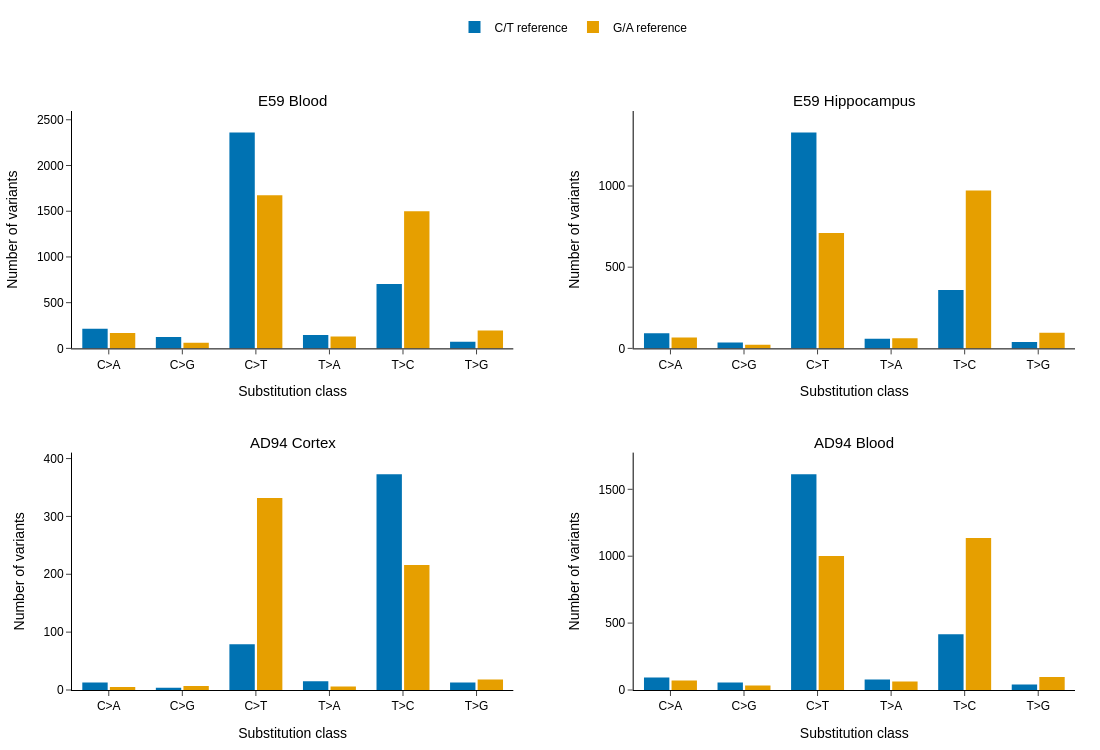

2026-10-29 14:57:20 - INFO - Chromium init'ed with kwargs {}
2026-10-29 14:57:20 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-29 14:57:20 - INFO - Temp directory created: /tmp/tmpa9cdludm.
2026-10-29 14:57:20 - INFO - Opening browser.
2026-10-29 14:57:20 - INFO - Temp directory created: /tmp/tmp2o0hl9a9.
2026-10-29 14:57:20 - INFO - Temporary directory at: /tmp/tmp2o0hl9a9
2026-10-29 14:57:21 - INFO - Conforming 1 to file:///tmp/tmpa9cdludm/index.html
2026-10-29 14:57:21 - INFO - Waiting on all navigates
2026-10-29 14:57:23 - INFO - All navigates done, putting them all in queue.
2026-10-29 14:57:23 - INFO - Getting tab from queue (has 1)
2026-10-29 14:57:23 - INFO - Got 2AB1
2026-10-29 14:57:23 - INFO - Processing fig.svg
2026-10-29 14:57:23 - INFO - Sending big command for fig.svg.
2026-10-29 14:57:23 - INFO - Sent big command for fig.svg.
2026-10-29 14:57:23 - INFO - 

In [103]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots


samples = {
    "E59 Blood": Surg_Bl,
    "E59 Hippocampus": Surg_Hip,
    "AD94 Cortex": Pm_Ctx,
    "AD94 Blood": Pm_Bl,
}

# Each pair contains complementary substitutions.
classes = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]

complementary_classes = {
    "C>A": "G>T",
    "C>G": "G>C",
    "C>T": "G>A",
    "T>A": "A>T",
    "T>C": "A>G",
    "T>G": "A>C",
}

colours = {
    "C/T reference": "#0072B2",
    "G/A reference": "#E69F00",
}


fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=list(samples.keys()),
    shared_yaxes=False,
    vertical_spacing=0.18,
    horizontal_spacing=0.12,
)


for i, (name, obj) in enumerate(samples.items()):
    row = i // 2 + 1
    col = i % 2 + 1

    variant_names = pd.Series(
        np.asarray(obj.uns["variant_names"]).ravel(),
        dtype="string",
    ).str.upper()

    # Variant names are formatted ALT-position-REF.
    parsed = variant_names.str.extract(
        r"^([ACGT])-(\d+)-([ACGT])$"
    )
    parsed.columns = ["alt", "position", "ref"]
    parsed = parsed.dropna()

    # Count each distinct variant once, excluding reference-equals-alt entries.
    parsed = parsed.loc[parsed["ref"] != parsed["alt"]].drop_duplicates()
    parsed["substitution"] = parsed["ref"] + ">" + parsed["alt"]

    counts = parsed["substitution"].value_counts()
    panel_counts = []

    for orientation, substitutions in [
        ("C/T reference", classes),
        (
            "G/A reference",
            [complementary_classes[mutation] for mutation in classes],
        ),
    ]:
        values = [
            int(counts.get(mutation, 0))
            for mutation in substitutions
        ]
        panel_counts.extend(values)

        fig.add_trace(
            go.Bar(
                x=classes,
                y=values,
                name=orientation,
                legendgroup=orientation,
                showlegend=(i == 0),
                marker=dict(
                    color=colours[orientation],
                    line=dict(width=0),
                ),
                customdata=np.asarray(substitutions),
                hovertemplate=(
                    "%{customdata}<br>"
                    "Variants: %{y}<extra></extra>"
                ),
            ),
            row=row,
            col=col,
        )

    # Scale each panel independently, retaining a zero baseline for bars.
    ymax = max(panel_counts, default=0)

    fig.update_yaxes(
        range=[0, max(1, ymax * 1.10)],
        autorange=False,
        title_text="Number of variants",
        row=row,
        col=col,
    )


fig.update_layout(
    template="simple_white",
    barmode="group",
    bargap=0.25,
    bargroupgap=0.08,
    width=1100,
    height=750,
    font=dict(
        family="Arial",
        size=12,
        color="black",
    ),
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=1.12,
        yanchor="bottom",
    ),
    margin=dict(l=70, r=25, t=100, b=60),
)


fig.update_xaxes(
    title_text="Substitution class",
    categoryorder="array",
    categoryarray=classes,
    showline=True,
    linewidth=1,
    linecolor="black",
    ticks="outside",
    showgrid=False,
)

fig.update_yaxes(
    showline=True,
    linewidth=1,
    linecolor="black",
    ticks="outside",
    showgrid=False,
)

fig.update_annotations(
    font=dict(
        family="Arial",
        size=15,
        color="black",
    )
)

fig.show(renderer="png")
fig.write_image(
    "mtDNA_substitution_counts.svg",
    width=1100,
    height=750,
)

In [52]:
import sys
sys.path.insert(0, '/mnt/claw-raid/elliot/P002_mtscATAC-seq/scripts/Py_mTCall_tools/Py_mTCall_tools')
import variant_calling_fast as vc
mgatk = vc.process_variants_fast("/mnt/claw-raid/elliot/P002_mtscATAC-seq/data/raw/241121-PBMC_results_masked/mgatk_output/final", Surg_BM, verbose=True, coverage_threshold=10, min_strand_count=2)


=== Fast Variant Calling Pipeline ===


You'll find variant names in adata.uns['variant_names']

Find coverage PER cell in adata.obsm['coverage_per_cell']

Variant summmary stats similar to Signac are in adata.uns['variant_summary']

Variant matrices are in adata.obsm["variant_vaf"]


=== IMPORTANT NOTE ===

Remember that variant VAFs are only included if they pass the min_strand_count filter

AND the coverage threshold if specified!



Loaded counts data: (132095, 8368)
Loaded coverage data: (131841933, 3)
Identifying variants (memory-optimized chunked method)...
Processing all 98891 variant observations (no artificial limits)
Integrating with AnnData...
=== Pipeline Complete ===
Processed 4701 variants in 68 matching cells


In [ ]:
#Nucleotide changes across samples 

In [ ]:
Surg_Hip = snap.pp.import_fragments(
    "/mnt/claw-raid/elliot/P002_mtscATAC-seq/data/raw/bm_epilepsy/outs/fragments.tsv.gz",
    chrom_sizes=snap.genome.hg38,
    sorted_by_barcode=False,
)

In [44]:
import plotly.graph_objects as go

fig = go.Figure()

for adata, name, colour in [
    (Pm_Bl, "Pm_Bl", "lightgrey"),
    (Surg_Bl, "Surg_Bl", "lightgrey"),
    (Surg_BM, "Surg_BM", "lightgrey"), 
    (Surg_Hip, "Surg_Hip", "lightgrey"),
    (Pm_Ctx, "Pm_Ctx", "lightgrey")
]:
    fig.add_trace(go.Violin(
        y=adata.obs["tsse"].dropna(),
        name=name,
        box_visible=True,
        points=False,
        fillcolor=colour,
        line_color="black",
        opacity=0.9,
        line_width=1.15,

    ))

fig.update_layout(
    template="simple_white",
    yaxis_title="TSS enrichment",
    xaxis_title="",
    showlegend=False,
    width=692,
    height=400, 
    font=dict(family="Arial", size=11, color="black")

)

fig.show()
fig.write_image("TSSE.svg", width=692, height=400)


2026-10-29 12:59:32 - INFO - Chromium init'ed with kwargs {}
2026-10-29 12:59:32 - INFO - Found chromium path: /home/elliot/miniconda3/envs/atac_env190516/lib/python3.10/site-packages/choreographer/cli/browser_exe/chrome-linux64/chrome
2026-10-29 12:59:32 - INFO - Temp directory created: /tmp/tmpjsos10bw.
2026-10-29 12:59:32 - INFO - Opening browser.
2026-10-29 12:59:32 - INFO - Temp directory created: /tmp/tmptemnvqre.
2026-10-29 12:59:32 - INFO - Temporary directory at: /tmp/tmptemnvqre


2026-10-29 12:59:33 - INFO - Conforming 1 to file:///tmp/tmpjsos10bw/index.html
2026-10-29 12:59:33 - INFO - Waiting on all navigates
2026-10-29 12:59:36 - INFO - All navigates done, putting them all in queue.
2026-10-29 12:59:36 - INFO - Getting tab from queue (has 1)
2026-10-29 12:59:36 - INFO - Got 4F71
2026-10-29 12:59:36 - INFO - Processing fig.svg
2026-10-29 12:59:36 - INFO - Sending big command for fig.svg.
2026-10-29 12:59:36 - INFO - Sent big command for fig.svg.
2026-10-29 12:59:36 - INFO - Reloading tab 4F71 before return.
2026-10-29 12:59:36 - INFO - Putting tab 4F71 back (queue size: 0).
2026-10-29 12:59:36 - INFO - Waiting for all cleanups to finish.
2026-10-29 12:59:36 - INFO - Exiting Kaleido
2026-10-29 12:59:36 - INFO - Closing browser.
2026-10-29 12:59:36 - INFO - Closing browser.
2026-10-29 12:59:36 - INFO - TemporaryDirectory.cleanup() worked.
2026-10-29 12:59:36 - INFO - shutil.rmtree worked.
2026-10-29 12:59:36 - INFO - Cancelling tasks.
2026-10-29 12:59:36 - INFO

In [19]:
snap.pp.select_features(Surg_BM, n_features=150000)
snap.pp.add_tile_matrix(Surg_BM)
snap.pp.scrublet(Surg_BM)
snap.pp.filter_doublets(Surg_BM)


2026-10-29 12:30:06 - INFO - Selected 150000 features.
2026-10-29 12:30:40 - INFO - Simulating doublets...
2026-10-29 12:30:41 - INFO - Spectral embedding ...
2026-10-29 12:33:00 - INFO - Calculating doublet scores...
2026-10-29 12:33:29 - INFO - Detected doublet rate = 3.285%


In [12]:
Pm_Bl = ad.read_h5ad('/mnt/claw-raid/elliot/P002_mtscATAC-seq/data/processed/atac_PM_blood/anndata_PBMC_PM.h5ad')

In [ ]:
#source code for TSSE plot  
import plotly.graph_objects as go

    selected_cells = adata.obs["n_fragment"] >= min_fragment
    x = adata.obs["n_fragment"][selected_cells]
    y = adata.obs["tsse"][selected_cells]

    log_x = np.log10(x)
    log_x_min, log_x_max = log_x.min(), log_x.max()
    x_range = log_x_max - log_x_min
    bin_x = np.linspace(log_x_min - 0.1 * x_range, log_x_max + 0.2 * x_range, 20)

    y_min, y_max = y.min(), y.max()
    y_range = y_max - y_min
    bin_y = np.linspace(y_min - 0.1 * y_range, y_max + 0.2 * y_range, 15)

    (z, rx, ry) = np.histogram2d(log_x,y, bins=(bin_x, bin_y))
    fig = go.Figure(data =
        go.Contour(
            z = z.T,
            x = 10**rx,
            y = ry,
            colorscale = 'Blues',
        )
    )

    if show_cells:
        fig.add_trace(go.Scatter(
                x = x,
                y = y,
                xaxis = 'x',
                yaxis = 'y',
                mode = 'markers',
                marker = dict(color = 'rgba(0,0,0,0.3)', size = 3)
        ))

    fig.update_xaxes(type="log")
    fig.update_layout(
        template="simple_white",
        xaxis_title="Number of unique fragments",
        yaxis_title="TSS enrichment score",
    )

    return render_plot(fig, width, height, interactive, show, out_file)


#cryo mt sc-atac code
qc_NB <- data.frame(Sample = NB$Sample, TSS_enrichment = NB$TSS.enrichment)
qc_GN <- data.frame(Sample = "GN01", TSS_enrichment = GN$TSS.enrichment)
qc_combined <- rbind(qc_NB, qc_GN)
qc_combined$Sample <- factor(qc_combined$Sample, levels = c(unique(seurat$Sample), "GN01"))

ggplot(qc_combined, aes(x = Sample, y = TSS_enrichment, fill = Sample)) +
  geom_violin(trim = FALSE, scale = "width", width = 0.9, alpha = 0.3) +
  geom_boxplot(width = 0.4, outlier.shape = NA, color = "black", alpha = 0.8) +
  scale_fill_manual(values = c("#76C3A9", "#355C4C", "#b37bb3")) +
  labs(y = "TSS enrichment", x = "") +       # Note: previously "nCount ATAC", should reflect TSS
  theme_classic() + ylim(0, 10) +
  theme(text = element_text(colour = "black", size = 15),
        axis.line = element_line(color = "black", size = 0.8),
        axis.text.x = element_text(colour = "black", size = 15, hjust = 1),
        axis.text.y = element_text(colour = "black", size = 15),
        axis.ticks.y = element_line(color = "black", size = 0.8),
        axis.ticks.x = element_line(color = "black", size = 0))